# Lecture 4b notebook: Tracking hidden states with the Kalman filter

Companion to Lecture 4b of *Systematic Trading Notes*. The sections follow the lecture: every number and
chart in the lecture is produced here, under the same section number.

1. The filter, bar by bar: how it starts, and when it is stable
2. Choosing the design: level only, level + slope, level + slope + acceleration, and what can be read from them
3. Setting the knobs: ratios and scale, one knob at a time, weights on past prices, memory in practice

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots
from scipy.stats import kurtosis, norm, skew

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "04-tracking-hidden-states" / "figures"
TICKERS = ["SPY", "QQQ", "GLD", "AGG"]

## Setup: data and the filter

Adjusted daily closes for SPY, QQQ, GLD and AGG, in logs. The function `kalman()` implements Table 1.3 of
the lecture; Table 1.6 maps each of its variables to the lecture's symbols.

In [2]:
ohlc = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb12_ohlc_long.csv")
O, H, L, C = (ohlc[f] for f in ("open", "high", "low", "close"))
for t in TICKERS:
    s = C[t].dropna()
    print(f"{t}: {s.index[0].date()} to {s.index[-1].date()}, {len(s)} bars")
qqq = C["QQQ"].dropna()
y_qqq = np.log(qqq.to_numpy())
dates = qqq.index

SPY: 1993-01-29 to 2026-10-09, 8482 bars
QQQ: 1999-03-10 to 2026-10-09, 6940 bars
GLD: 2004-11-18 to 2026-10-09, 5507 bars
AGG: 2003-09-29 to 2026-10-09, 5795 bars


In [3]:
def kalman(prices, transition, observe, q_diag, r_price, start_uncertainty=1.0, start_state=None,
           cap=None, r_series=None, full_q=None):
    n = transition.shape[0]
    state = np.zeros(n)
    state[0] = prices[0]
    if start_state is not None:
        state = np.array(start_state, dtype=float)
    uncertainty = np.eye(n) * start_uncertainty
    Q = np.diag(q_diag) if full_q is None else full_q
    T = len(prices)
    out = {k: np.empty(T) for k in ("forecast", "surprise", "z", "gain", "surprise_var")}
    states, sds = np.empty((T, n)), np.empty((T, n))
    z_var = 1.0                                                        # running scale of recent surprises (robust update)
    for t, price in enumerate(prices):
        r = r_price if r_series is None else r_series[t]
        state = transition @ state                                     # predict
        uncertainty = transition @ uncertainty @ transition.T + Q
        forecast = observe @ state
        surprise_var = observe @ uncertainty @ observe + r
        gain = uncertainty @ observe / surprise_var                    # trust in the new price
        surprise = price - forecast                                    # compare
        z = surprise / np.sqrt(surprise_var)
        used = surprise
        if cap is not None:
            limit = cap * np.sqrt(z_var)                                   # cap relative to the recent typical surprise
            if abs(z) > limit:
                used = np.sign(surprise) * limit * np.sqrt(surprise_var)
            z_var = (1 - 1 / 252) * z_var + (1 / 252) * min(z ** 2, limit ** 2)   # updated with past data only
        state = state + gain * used                                    # correct
        uncertainty = uncertainty - np.outer(gain, observe @ uncertainty)
        states[t], sds[t] = state, np.sqrt(np.diag(uncertainty))
        for k, v in (("forecast", forecast), ("surprise", surprise), ("z", z), ("gain", gain[0]),
                     ("surprise_var", surprise_var)):
            out[k][t] = v
    out["states"], out["sd"] = states, sds
    return out


def design(n_states, damping=1.0):
    if n_states == 1:
        return np.array([[1.0]]), np.array([1.0])
    if n_states == 2:
        return np.array([[1.0, 1.0], [0.0, damping]]), np.array([1.0, 0.0])
    return np.array([[1.0, 1.0, 0.5], [0.0, 1.0, 1.0], [0.0, 0.0, 1.0]]), np.array([1.0, 0.0, 0.0])


Q_REL = {1: np.array([1.0]), 2: np.array([1.0, 1e-2]), 3: np.array([1.0, 1e-2, 1e-4])}
NAMES = {1: "Level only", 2: "Level + slope", 3: "Level + slope + acceleration"}


def run(prices, k, r_price, q_scale=1e-4, damping=1.0, **kw):
    F, Hh = design(k, damping)
    return kalman(prices, F, Hh, Q_REL[k] * q_scale, r_price, **kw)


def ema(x, alpha):
    out = np.empty(len(x)); out[0] = x[0]
    for t in range(1, len(x)):
        out[t] = alpha * x[t] + (1 - alpha) * out[t - 1]
    return out

## 1. The filter, bar by bar

**How the filter starts (Lecture 4b, Tables 1.4 and 1.5).** The three-state design on the made-up prices 50, 52,
55, 57; then the gains run forward without any prices, to find the bar from which every gain stays within 1%
of its final value.

In [4]:
F3t, H3t = design(3)
Q_toy, r_toy = np.diag([1e-4, 1e-6, 1e-8]), 1.0
x_t, P_t = np.array([50.0, 0.0, 0.0]), np.eye(3) * 1e6
rows = {}
for bar, price in enumerate([50.0, 52.0, 55.0, 57.0], start=1):
    x_pred = F3t @ x_t                                      # step 1
    P_pred = F3t @ P_t @ F3t.T + Q_toy                      # step 2
    y_hat = H3t @ x_pred                                    # step 3
    S_toy = H3t @ P_pred @ H3t + r_toy                      # step 4
    K_toy = P_pred @ H3t / S_toy                            # step 5
    e_toy = price - y_hat                                   # step 6
    x_t = x_pred + K_toy * e_toy                            # step 7
    P_t = P_pred - np.outer(K_toy, H3t @ P_pred)            # step 8
    rows[bar] = {"price": price, "predicted state (1)": np.round(x_pred, 2).tolist(), "predicted sd (2)": np.round(np.sqrt(np.diag(P_pred)), 1).tolist(), "forecast (3)": y_hat, "sqrt S (4)": np.sqrt(S_toy),
                 "gains (5)": np.round(K_toy, 3).tolist(), "surprise (6)": e_toy,
                 "level/slope/acc (7)": np.round(x_t, 3).tolist(), "sd (8)": np.round(np.sqrt(np.diag(P_t)), 3).tolist()}
display(pd.DataFrame(rows).T)

P_g, gains = np.eye(3) * 1e6, []
for _ in range(5000):                                     # gains need no prices
    P_pred = F3t @ P_g @ F3t.T + Q_toy
    K_g = P_pred @ H3t / (H3t @ P_pred @ H3t + r_toy)
    P_g = P_pred - np.outer(K_g, H3t @ P_pred)
    gains.append(K_g)
gains = np.array(gains)
print(pd.DataFrame(gains[[3, 9, 49, 99, 199]], index=[4, 10, 50, 100, 200], columns=["level", "slope", "acceleration"]).round(4))
settled = max(int(np.where(np.abs(gains[:, i] - gains[-1, i]) > 0.01 * gains[-1, i])[0][-1]) + 2 for i in range(3))
print(f"every gain within 1% of its final value from bar {settled}")

,price,predicted state (1),predicted sd (2),forecast (3),sqrt S (4),gains (5),surprise (6),level/slope/acc (7),sd (8)
1,50.0,"[50.0, 0.0, 0.0]","[1500.0, 1414.2, 1000.0]",50.0,1500.000333,"[1.0, 0.667, 0.222]",0.0,"[50.0, 0.0, 0.0]","[1.0, 1000.0, 942.809]"
2,52.0,"[50.0, 0.0, 0.0]","[1374.4, 1795.1, 942.8]",50.0,1374.370056,"[1.0, 1.294, 0.588]",2.0,"[52.0, 2.588, 1.176]","[1.0, 242.543, 485.072]"
3,55.0,"[55.18, 3.76, 1.18]","[485.1, 727.6, 485.1]",55.176464,485.082614,"[1.0, 1.5, 1.0]",-0.176464,"[55.0, 3.5, 1.0]","[1.0, 2.55, 2.449]"
4,57.0,"[59.0, 4.5, 1.0]","[4.4, 4.9, 2.4]",59.000014,4.472127,"[0.95, 1.05, 0.5]",-2.000014,"[57.1, 2.4, 0.0]","[0.975, 1.565, 1.0]"


      level   slope  acceleration
4    0.9500  1.0500        0.5000
10   0.6182  0.2591        0.0455
50   0.1671  0.0136        0.0005
100  0.0966  0.0046        0.0001
200  0.0908  0.0043        0.0001
every gain within 1% of its final value from bar 121


## 2. Choosing the design

**Level only is an EMA (§2.1).** Lecture 2's toy series, filtered with the level-only design at $q/r = 1/6$:
the steady gain is exactly $1/3$, the $\alpha$ of EMA(5), and the level reproduces EMA(5) bar for bar.

In [5]:
toy = np.array([100, 100.3, 100.5, 100.8, 101.0, 101.3, 101.5, 108.5, 102.5, 102.8, 103.0, 103.3, 103.5, 103.8])
r_toy, q_toy = 1.0, 1.0 / 6.0
u_star = (q_toy + np.sqrt(q_toy ** 2 + 4 * q_toy * r_toy)) / 2
gain_star = u_star / (u_star + r_toy)
F1, H1 = design(1)
res = kalman(toy, F1, H1, np.array([q_toy]), r_toy, start_uncertainty=(1 - gain_star) * u_star)
ema5 = ema(toy, 1 / 3)
tab = pd.DataFrame({"price": toy, "forecast": res["forecast"], "surprise": res["surprise"],
                    "gain": res["gain"], "level": res["states"][:, 0], "EMA(5)": ema5}).round(3)
tab.index.name = "bar"
print(f"steady-state gain = {gain_star:.4f} (EMA(5) alpha = 1/3)")
display(tab)
assert np.allclose(res["states"][:, 0], ema5)
t7 = 7
print(f"bar 7 by hand: forecast {res['forecast'][t7]:.3f}, surprise {toy[t7]:.1f} - {res['forecast'][t7]:.3f} = {res['surprise'][t7]:.3f}, "
      f"level = {res['forecast'][t7]:.3f} + {res['gain'][t7]:.4f} x {res['surprise'][t7]:.3f} = {res['states'][t7, 0]:.3f}")

steady-state gain = 0.3333 (EMA(5) alpha = 1/3)


,price,forecast,surprise,gain,level,EMA(5)
bar,,,,,,
0,100.0,100.000,0.000,0.333,100.000,100.000
1,100.3,100.000,0.300,0.333,100.100,100.100
2,100.5,100.100,0.400,0.333,100.233,100.233
3,100.8,100.233,0.567,0.333,100.422,100.422
4,101.0,100.422,0.578,0.333,100.615,100.615
5,101.3,100.615,0.685,0.333,100.843,100.843
6,101.5,100.843,0.657,0.333,101.062,101.062
7,108.5,101.062,7.438,0.333,103.541,103.541
8,102.5,103.541,-1.041,0.333,103.194,103.194


bar 7 by hand: forecast 101.062, surprise 108.5 - 101.062 = 7.438, level = 101.062 + 0.3333 x 7.438 = 103.541


**What each design can follow (§2.4).** Each design at a slow and a fast setting, on a jump, a steady trend and
a parabolic move, with no noise (price noise $r = 1$).

In [6]:
tt = np.arange(3000.0)
tests = {"jump of 1": np.where(tt < 100, 0.0, 1.0), "steady trend (+0.01 per bar)": 0.01 * tt,
         "parabolic (1e-5 t^2)": 1e-5 * tt ** 2}
speeds = {"slow": np.array([1e-4, 1e-6, 1e-8]), "fast": np.array([1e-2, 1e-3, 1e-4])}
rows = []
for k in (1, 2, 3):
    F, Hh = design(k)
    row = {"design": NAMES[k]}
    for sp, q in speeds.items():
        lv = {name: kalman(y, F, Hh, q[:k], 1.0, start_uncertainty=1e3)["states"][:, 0] for name, y in tests.items()}
        row[f"jump overshoot, {sp} (%)"] = round(max(0.0, lv["jump of 1"][100:].max() - 1) * 100, 1)
        for name in ("steady trend (+0.01 per bar)", "parabolic (1e-5 t^2)"):
            y = tests[name]
            row[f"{name.split(' (')[0]} gap at bar 1500 / 2999, {sp}"] = f"{y[1500] - lv[name][1500]:.4f} / {y[2999] - lv[name][2999]:.4f}"
    rows.append(row)
design_tab = pd.DataFrame(rows).set_index("design")
display(design_tab.T)

design,Level only,Level + slope,Level + slope + acceleration
"jump overshoot, slow (%)",0.0,19.7,28.8
"steady trend gap at bar 1500 / 2999, slow",0.9950 / 0.9950,0.0000 / -0.0000,0.0000 / 0.0000
"parabolic gap at bar 1500 / 2999, slow",2.7860 / 5.7691,0.0195 / 0.0195,-0.0000 / 0.0000
"jump overshoot, fast (%)",0.0,16.6,23.0
"steady trend gap at bar 1500 / 2999, fast",0.0951 / 0.0951,-0.0000 / 0.0000,0.0000 / 0.0000
"parabolic gap at bar 1500 / 2999, fast",0.2835 / 0.5687,0.0006 / 0.0006,0.0000 / -0.0000


**What can be read from the filter (§2.5; charts C.1 to C.4).**

The quantities of Lecture 4b, Table 2.4, on QQQ, with memories suited to longer-term charts:

- **Level + slope design (LS):** the level reacts to each surprise like EMA(15) (steady gain $2/16$), and the
  slope's weights on past prices reach back as far as those of EMA(90) (to 0.1% of their total weight).
  Used for the level, the bands, the slope, the stretch and the surprises.
- **Three-state design (LSA):** same $q_\ell$ and $q_s$, with $q_a$ chosen so that the acceleration's weights
  reach back as far as those of EMA(45). Used for the acceleration only: in one three-state filter the slope
  cannot keep a longer memory than the acceleration, so this filter's slope becomes faster.

Price noise $r = 10^{-4}$; diffuse start on the first bar of QQQ.

LS:  q_level = 0.01293 r, q_slope = 6.05e-06 r; level gain 0.125; slope horizon 311 bars (EMA(90): 311)
LSA: q_acc = 2.99e-07 r; horizons level / slope / acceleration 147 / 156 / 156 bars (EMA(45): 156)


calibrated price noise r = 0.000329 (a daily price noise of 1.81%)


steady sd of the level: 0.64% ; steady sqrt(S): 1.94%


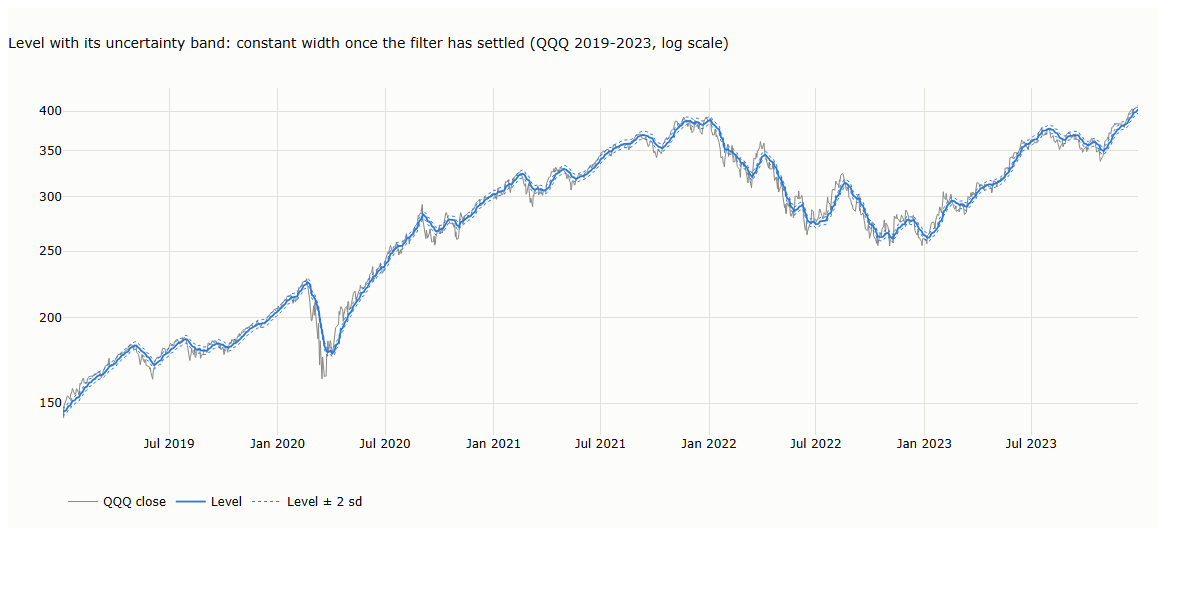

In [7]:
def steady_weights_k(q_rel, n=8000):
    k = len(q_rel); F_k, H_k = design(k); Q_k = np.diag(q_rel); P_k = np.eye(k)
    for _ in range(400000):
        Pp = F_k @ P_k @ F_k.T + Q_k; K_k = Pp @ H_k / (H_k @ Pp @ H_k + 1.0); Pn = Pp - np.outer(K_k, H_k @ Pp)
        if np.allclose(Pn, P_k, rtol=1e-12, atol=0): break
        P_k = Pn
    A_k = (np.eye(k) - np.outer(K_k, H_k)) @ F_k
    W, v = np.empty((n, k)), K_k.copy()
    for j in range(n):
        W[j] = v; v = A_k @ v
    return K_k, W


def tail_horizon(w):
    tail = np.cumsum(np.abs(w)[::-1])[::-1] / np.abs(w).sum()
    return int(np.argmax(tail < 1e-3))


def bisect(f, target, lo, hi, increasing):
    for _ in range(70):
        m = np.sqrt(lo * hi)
        lo, hi = (m, hi) if (f(m) < target) == increasing else (lo, m)
    return m


ema_horizon = lambda N: int(np.ceil(np.log(1e-3) / np.log(1 - 2 / (N + 1))))
ql_rel = 0.05
for _ in range(6):                      # alternate: slope memory = EMA(90), level gain = 2/16
    qs_rel = bisect(lambda q: tail_horizon(steady_weights_k([ql_rel, q])[1][:, 1]), ema_horizon(90), 1e-14, 1e-1, increasing=False)
    ql_rel = bisect(lambda q: steady_weights_k([q, qs_rel])[0][0], 2 / 16, 1e-6, 10, increasing=True)
qa_rel = bisect(lambda q: tail_horizon(steady_weights_k([ql_rel, qs_rel, q])[1][:, 2]), ema_horizon(45), 1e-16, 1e-2, increasing=False)
K2s, W2s = steady_weights_k([ql_rel, qs_rel]); K3s, W3s = steady_weights_k([ql_rel, qs_rel, qa_rel])
print(f"LS:  q_level = {ql_rel:.4g} r, q_slope = {qs_rel:.3g} r; level gain {K2s[0]:.3f}; slope horizon {tail_horizon(W2s[:, 1])} bars (EMA(90): {ema_horizon(90)})")
print(f"LSA: q_acc = {qa_rel:.3g} r; horizons level / slope / acceleration {tail_horizon(W3s[:, 0])} / {tail_horizon(W3s[:, 1])} / {tail_horizon(W3s[:, 2])} bars (EMA(45): {ema_horizon(45)})")

# The ratios fix the estimates; the scale of r fixes the uncertainty. Calibrate the scale so that the normalised
# surprises have variance 1 over 2014-2018, before the charted period (no look-ahead).
r_b = 1e-4
cal = (dates >= "2014-01-01") & (dates <= "2018-12-31")
z_trial = kalman(y_qqq, *design(2), np.array([ql_rel, qs_rel]) * r_b, r_b, start_uncertainty=1.0)["z"]
r_b *= np.mean(z_trial[cal] ** 2)
print(f"calibrated price noise r = {r_b:.3g} (a daily price noise of {100 * np.sqrt(r_b):.2f}%)")
LS_b = kalman(y_qqq, *design(2), np.array([ql_rel, qs_rel]) * r_b, r_b, start_uncertainty=1.0)
LSA_b = kalman(y_qqq, *design(3), np.array([ql_rel, qs_rel, qa_rel]) * r_b, r_b, start_uncertainty=1.0)
lvl, sl = LS_b["states"][:, 0], LS_b["states"][:, 1]
sd_lvl, sd_sl = LS_b["sd"][:, 0], LS_b["sd"][:, 1]
acc, sd_acc = LSA_b["states"][:, 2], LSA_b["sd"][:, 2]
z_b = LS_b["z"]
px = pd.Series(qqq.to_numpy(), dates)
win = (dates >= "2019-01-01") & (dates <= "2023-12-31")
print(f"steady sd of the level: {100 * sd_lvl[-1]:.2f}% ; steady sqrt(S): {100 * np.sqrt(LS_b['surprise_var'][-1]):.2f}%")

# C.1 level with its band
fig = go.Figure()
d = dates[win]
fig.add_scatter(x=d, y=px[win], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED))
fig.add_scatter(x=d, y=np.exp(lvl[win]), name="Level", mode="lines", line=dict(width=1.8, color=SERIES[0]))
fig.add_scatter(x=d, y=np.exp(lvl[win] + 2 * sd_lvl[win]), name="Level ± 2 sd", mode="lines", line=dict(width=1, color=SERIES[0], dash="dot"))
fig.add_scatter(x=d, y=np.exp(lvl[win] - 2 * sd_lvl[win]), showlegend=False, mode="lines", line=dict(width=1, color=SERIES[0], dash="dot"))
fig.update_layout(title="Level with its uncertainty band: constant width once the filter has settled (QQQ 2019-2023, log scale)",
                  yaxis=dict(type="log"), height=520, width=1150, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "b_c01_level_bands", FIG)
fig

2019-2023: slope more than 2 sd above zero on 59% of days, below on 17%


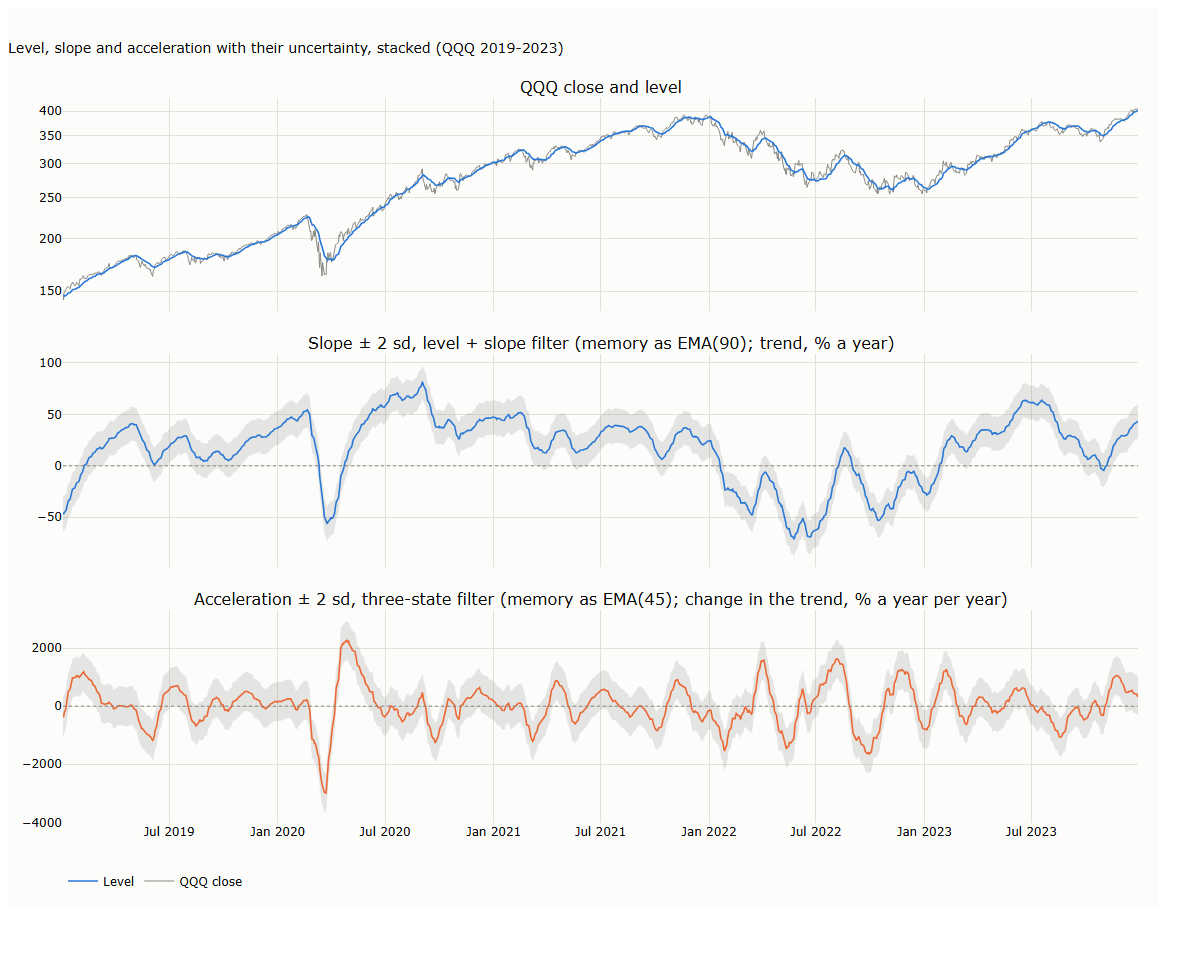

In [8]:
# C.2 price, slope and acceleration, stacked
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                    subplot_titles=("QQQ close and level", "Slope ± 2 sd, level + slope filter (memory as EMA(90); trend, % a year)", "Acceleration ± 2 sd, three-state filter (memory as EMA(45); change in the trend, % a year per year)"))
fig.add_scatter(x=d, y=px[win], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
fig.add_scatter(x=d, y=np.exp(lvl[win]), name="Level", mode="lines", line=dict(width=1.6, color=SERIES[0]), row=1, col=1)
for row, (v, sdv, scale, col) in ((2, (sl, sd_sl, 25200, SERIES[0])), (3, (acc, sd_acc, 25200 * 252, SERIES[1]))):
    fig.add_scatter(x=d, y=scale * (v + 2 * sdv)[win], showlegend=False, mode="lines", line=dict(width=0), row=row, col=1)
    fig.add_scatter(x=d, y=scale * (v - 2 * sdv)[win], showlegend=False, mode="lines", line=dict(width=0), fill="tonexty",
                    fillcolor="rgba(120,120,120,0.18)", row=row, col=1)
    fig.add_scatter(x=d, y=scale * v[win], showlegend=False, mode="lines", line=dict(width=1.6, color=col), row=row, col=1)
    fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=row, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_layout(title="Level, slope and acceleration with their uncertainty, stacked (QQQ 2019-2023)", height=900, width=1150,
                  margin=dict(t=90, b=60), legend=dict(orientation="h", y=-0.06, x=0))
save_figure(fig, "b_c02_slope_acceleration", FIG)
pos = sl[win] > 2 * sd_sl[win]; neg = sl[win] < -2 * sd_sl[win]
print(f"2019-2023: slope more than 2 sd above zero on {100 * pos.mean():.0f}% of days, below on {100 * neg.mean():.0f}%")
fig

stretch 2019-2023: 5th / 95th percentile -4.4% / 4.0%; extremes -16.8% / 9.3%


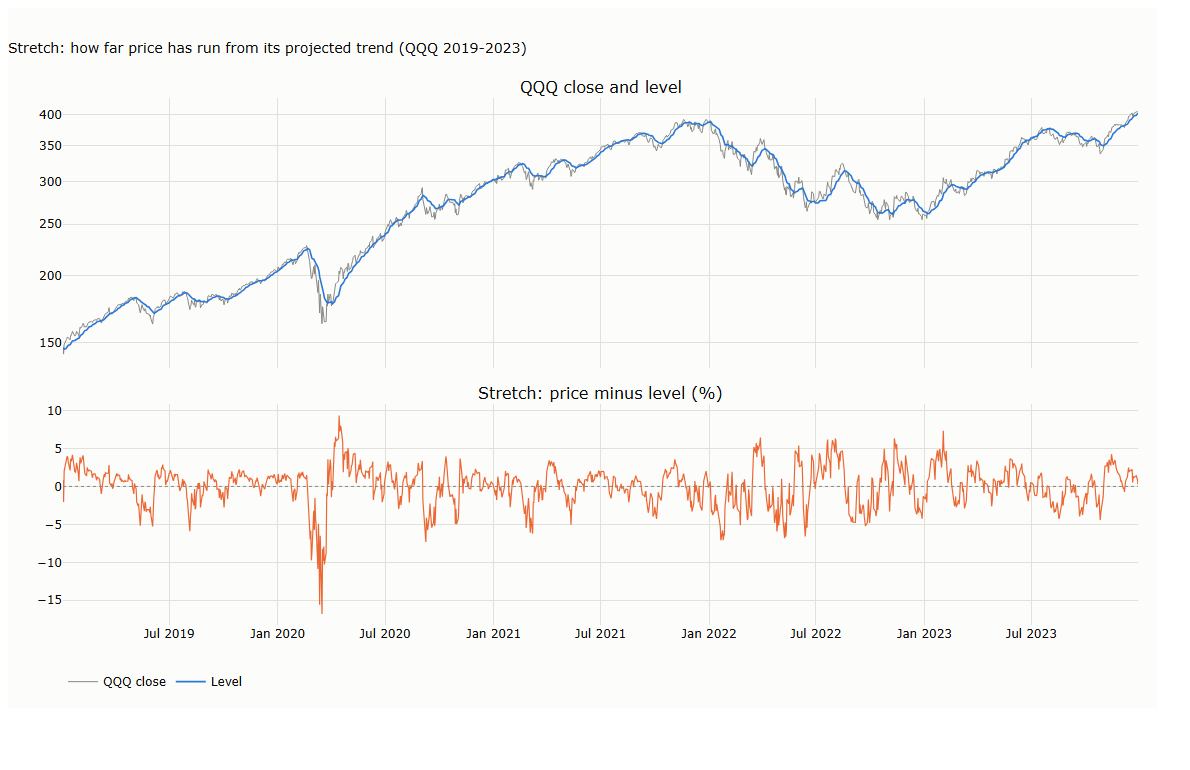

In [9]:
# C.3 stretch
stretch = 100 * (y_qqq - lvl)
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.07, row_heights=[0.55, 0.45],
                    subplot_titles=("QQQ close and level", "Stretch: price minus level (%)"))
fig.add_scatter(x=d, y=px[win], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
fig.add_scatter(x=d, y=np.exp(lvl[win]), name="Level", mode="lines", line=dict(width=1.6, color=SERIES[0]), row=1, col=1)
fig.add_scatter(x=d, y=stretch[win], showlegend=False, mode="lines", line=dict(width=1.2, color=SERIES[1]), row=2, col=1)
fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=2, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_layout(title="Stretch: how far price has run from its projected trend (QQQ 2019-2023)", height=700, width=1150,
                  margin=dict(t=90, b=60), legend=dict(orientation="h", y=-0.08, x=0))
save_figure(fig, "b_c03_stretch", FIG)
print(f"stretch 2019-2023: 5th / 95th percentile {np.percentile(stretch[win], 5):.1f}% / {np.percentile(stretch[win], 95):.1f}%; extremes {stretch[win].min():.1f}% / {stretch[win].max():.1f}%")
fig

share of days beyond ±3: 6.46% (normal: 0.27%); standard deviation of z: 1.60; 2014-2018: 1.00
days beyond ±3 by year (top 6): {2001: 109, 2000: 67, 2002: 61, 2008: 36, 2022: 32, 2020: 31}


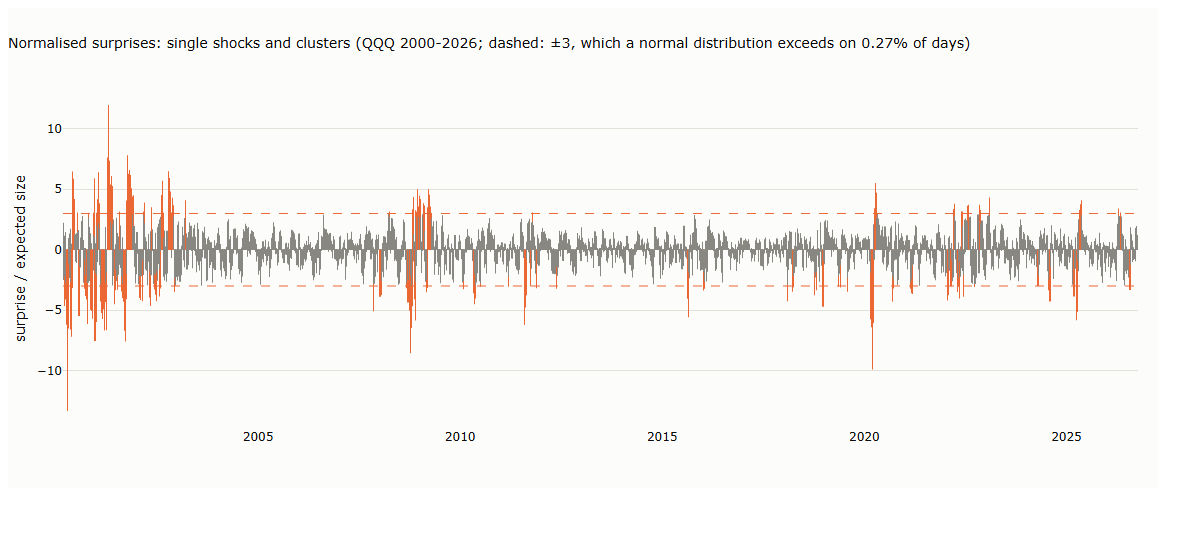

In [10]:
# C.4 normalised surprises, full history
zz = pd.Series(z_b, dates).iloc[250:]
fig = go.Figure()
fig.add_bar(x=zz.index, y=zz, name="Normalised surprise e/sqrt(S)", marker=dict(color=np.where(zz.abs() > 3, SERIES[1], MUTED), line=dict(width=0)))
for lv in (-3, 3):
    fig.add_hline(y=lv, line=dict(width=1, color=SERIES[1], dash="dash"))
fig.update_layout(title="Normalised surprises: single shocks and clusters (QQQ 2000-2026; dashed: ±3, which a normal distribution exceeds on 0.27% of days)",
                  yaxis_title="surprise / expected size", height=480, width=1150, margin=dict(t=80, b=60), showlegend=False)
save_figure(fig, "b_c04_surprises", FIG)
big = zz.abs() > 3
by_year = big.groupby(zz.index.year).sum()
print(f"share of days beyond ±3: {100 * big.mean():.2f}% (normal: 0.27%); standard deviation of z: {zz.std():.2f}; 2014-2018: {zz['2014':'2018'].std():.2f}")
print("days beyond ±3 by year (top 6):", by_year.sort_values(ascending=False).head(6).to_dict())
fig

## 3. Setting the knobs

**Ratios set the speed; the scale sets the uncertainty (§3.1; Table 3.1, chart C.5).** The same ten prices,
filtered with $(q, r) = (1, 4)$ and $(10, 40)$, with the starting uncertainty scaled by the same factor.

,price,"level (q=1, R=4)","level (q=10, R=40)",gain A,gain B,band A (+-1 sd),band B (+-1 sd)
0,100.0,100.000,100.000,1.000,1.000,2.000,6.325
1,101.0,100.556,100.556,0.556,0.556,1.491,4.714
2,99.0,99.862,99.862,0.446,0.446,1.336,4.224
3,102.0,100.739,100.739,0.410,0.410,1.281,4.052
4,104.0,102.036,102.036,0.398,0.398,1.261,3.989
5,103.0,102.415,102.415,0.393,0.393,1.254,3.965
6,107.0,104.210,104.210,0.391,0.391,1.251,3.957
7,106.0,104.909,104.909,0.391,0.391,1.250,3.954
8,108.0,106.116,106.116,0.391,0.391,1.250,3.952
9,110.0,107.633,107.633,0.390,0.390,1.250,3.952


band ratio B/A at the last bar: 3.162 (sqrt(10) = 3.162)


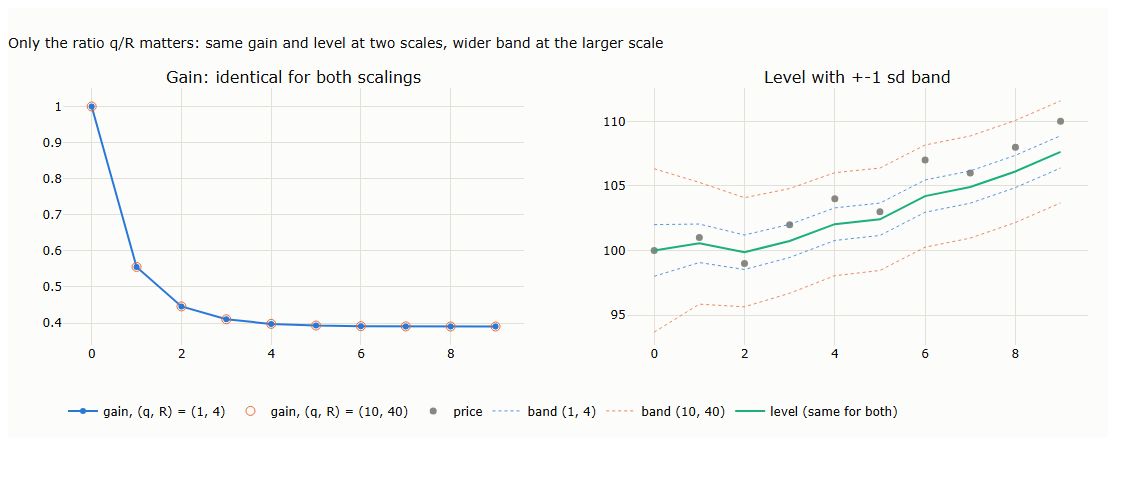

In [11]:
prices10 = np.array([100, 101, 99, 102, 104, 103, 107, 106, 108, 110.0])
A = kalman(prices10, F1, H1, np.array([1.0]), 4.0, start_uncertainty=1e6)
B = kalman(prices10, F1, H1, np.array([10.0]), 40.0, start_uncertainty=1e7)   # every variance scaled by 10, including the start
ratio_tab = pd.DataFrame({"price": prices10, "level (q=1, R=4)": A["states"][:, 0], "level (q=10, R=40)": B["states"][:, 0],
                          "gain A": A["gain"], "gain B": B["gain"], "band A (+-1 sd)": A["sd"][:, 0], "band B (+-1 sd)": B["sd"][:, 0]}).round(3)
display(ratio_tab)
assert np.allclose(A["states"], B["states"]) and np.allclose(A["gain"], B["gain"])
print(f"band ratio B/A at the last bar: {B['sd'][-1, 0] / A['sd'][-1, 0]:.3f} (sqrt(10) = {np.sqrt(10):.3f})")

fig = make_subplots(rows=1, cols=2, subplot_titles=("Gain: identical for both scalings", "Level with +-1 sd band"))
fig.add_scatter(x=np.arange(10), y=A["gain"], name="gain, (q, R) = (1, 4)", mode="lines+markers", line=dict(color=SERIES[0], width=2), row=1, col=1)
fig.add_scatter(x=np.arange(10), y=B["gain"], name="gain, (q, R) = (10, 40)", mode="markers", marker=dict(color=SERIES[1], size=9, symbol="circle-open"), row=1, col=2 - 1)
fig.add_scatter(x=np.arange(10), y=prices10, name="price", mode="markers", marker=dict(color=MUTED, size=7), row=1, col=2)
for j, (lab, R_) in enumerate((("(1, 4)", A), ("(10, 40)", B))):
    lvl, sd = R_["states"][:, 0], R_["sd"][:, 0]
    fig.add_scatter(x=np.arange(10), y=lvl + sd, mode="lines", line=dict(width=0.8, color=SERIES[j], dash="dot"), showlegend=False, row=1, col=2)
    fig.add_scatter(x=np.arange(10), y=lvl - sd, mode="lines", line=dict(width=0.8, color=SERIES[j], dash="dot"), name=f"band {lab}", row=1, col=2)
fig.add_scatter(x=np.arange(10), y=A["states"][:, 0], name="level (same for both)", mode="lines", line=dict(color=SERIES[2], width=2), row=1, col=2)
fig.update_layout(title="Only the ratio q/R matters: same gain and level at two scales, wider band at the larger scale",
                  height=430, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c02_ratio_invariance", FIG)
fig

**Turning one knob at a time (§3.2; Table 3.2, chart C.6).** The three-state design with four noise settings,
each raising one $q$ a hundredfold from a balanced case ($r = 10^{-4}$). The settings are illustrative.

,level roughness,level gap to price (RMS %),slope sign changes per year,days until slope < 0 after 2020-02-19 peak,days until slope > 0 after 2020-03-23 low
Balanced,0.33,2.24,8.01,6.0,15.0
Level emphasised,0.66,0.64,9.45,6.0,15.0
Slope emphasised,0.51,1.28,24.67,3.0,3.0
Acceleration emphasised,0.43,1.79,14.88,4.0,6.0


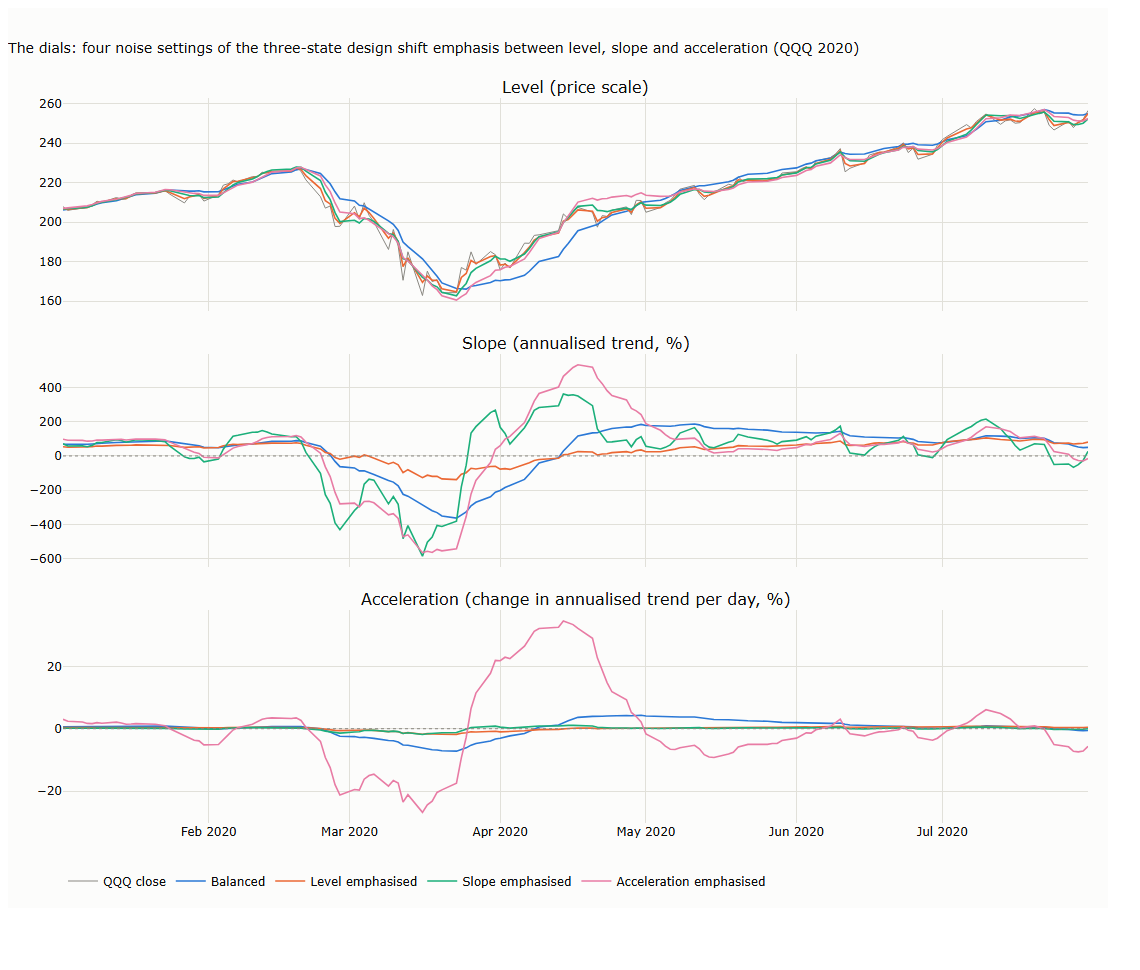

In [12]:
F3, H3 = design(3)
settings = {"Balanced": (1e-6, 1e-8, 1e-11), "Level emphasised": (1e-4, 1e-8, 1e-11),
            "Slope emphasised": (1e-6, 1e-6, 1e-11), "Acceleration emphasised": (1e-6, 1e-8, 1e-9)}
m = (dates >= "2020-01-01") & (dates <= "2020-07-31")
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                    subplot_titles=("Level (price scale)", "Slope (annualised trend, %)", "Acceleration (change in annualised trend per day, %)"))
fig.add_scatter(x=dates[m], y=qqq.to_numpy()[m], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
rows = {}
for j, (nm, q) in enumerate(settings.items()):
    Xs = kalman(y_qqq, F3, H3, np.array(q), 1e-4)["states"]
    for r_, (col, scale) in enumerate(((0, None), (1, 25200), (2, 25200)), start=1):
        yv = np.exp(Xs[m, 0]) if col == 0 else scale * Xs[m, col]
        fig.add_scatter(x=dates[m], y=yv, name=nm, showlegend=(r_ == 1), mode="lines", line=dict(width=1.6, color=SERIES[j]), row=r_, col=1)
    lvl, sl, yy = Xs[300:, 0], Xs[300:, 1], y_qqq[300:]
    s = pd.Series(Xs[:, 1], dates)

    def turn(d, sign):
        w = s.loc[d:]
        hit = w[np.sign(w) == sign]
        return dates.get_loc(hit.index[0]) - dates.get_loc(w.index[0])

    rows[nm] = {"level roughness": np.std(np.diff(lvl)) / np.std(np.diff(yy)), "level gap to price (RMS %)": 100 * np.sqrt(np.mean((lvl - yy) ** 2)),
                "slope sign changes per year": np.sum(np.diff(np.sign(sl)) != 0) / (len(sl) / 252),
                "days until slope < 0 after 2020-02-19 peak": turn("2020-02-19", -1), "days until slope > 0 after 2020-03-23 low": turn("2020-03-23", 1)}
for r_ in (2, 3):
    fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=r_, col=1)
fig.update_layout(title="The dials: four noise settings of the three-state design shift emphasis between level, slope and acceleration (QQQ 2020)",
                  height=900, width=1100, margin=dict(t=90, b=70), legend=dict(orientation="h", y=-0.06, x=0))
save_figure(fig, "c06_dials", FIG)
display(pd.DataFrame(rows).T.round(2))
fig

The overshoot of the acceleration setting in price terms: its slope against the fastest 20-day pace QQQ reached.

In [13]:
pace = pd.Series(y_qqq, dates).diff(20) * 252 / 20
w = slice("2020-03-23", "2020-06-30")
print(f"QQQ fastest 20-day pace after the March low: {100 * pace[w].max():.0f}% annualised ({pace[w].idxmax().date()})")
rows = {}
for nm, q in settings.items():
    Xs = pd.DataFrame(kalman(y_qqq, F3, H3, np.array(q), 1e-4)["states"], index=dates)
    sl, gap = Xs[1][w], np.exp(Xs[0] - y_qqq)[w] - 1
    t0 = sl.idxmax(); i0 = dates.get_loc(t0)
    rows[nm] = {"peak slope (% a year)": 100 * 252 * sl.max(), "date": t0.date(),
                "next 21 days implied by the slope (%)": 100 * (np.exp(21 * sl.max()) - 1),
                "next 21 days realised (%)": 100 * (qqq.iloc[i0 + 21] / qqq.iloc[i0] - 1),
                "largest level above price (%)": 100 * gap.max()}
display(pd.DataFrame(rows).T.round(1))

QQQ fastest 20-day pace after the March low: 285% annualised (2020-04-14)


,peak slope (% a year),date,next 21 days implied by the slope (%),next 21 days realised (%),largest level above price (%)
Balanced,186.211364,2020-05-11,16.786365,8.529101,4.106999
Level emphasised,87.158287,2020-06-10,7.533464,7.395432,1.875608
Slope emphasised,361.675492,2020-04-14,35.174485,3.530634,4.310706
Acceleration emphasised,531.632248,2020-04-17,55.741419,5.638904,6.953803


**Weights on past prices (§3.3; chart C.7).** In steady state every design is a fixed weighted average of past
prices; the weights are read off its response to a single unit price. The three designs are matched to EMA(20)
on how much they smooth (variance reduction $\sum_k w_k^2 = 1/20$), so that they can be compared.

In [14]:
def level_weights(k, r_price, n=400, warm=3000, **kw):
    z = np.zeros(warm + n)
    base = run(z, k, r_price, **kw)["states"][:, 0]
    z[warm] = 1.0
    return (run(z, k, r_price, **kw)["states"][:, 0] - base)[warm:]


def match_r(k, target_vrf=1 / 20, **kw):
    lo, hi = 1e-7, 1e4
    for _ in range(70):
        mid = np.sqrt(lo * hi)
        w = level_weights(k, mid, **kw)
        lo, hi = (mid, hi) if (w ** 2).sum() / w.sum() ** 2 > target_vrf else (lo, mid)
    return mid


R_MATCH = {k: match_r(k) for k in (1, 2, 3)}
alpha20 = 2 / 21
rows = {}
for k in (1, 2, 3):
    w = level_weights(k, R_MATCH[k])
    ages = np.arange(len(w))
    rows[NAMES[k]] = {"price noise R (matched)": R_MATCH[k], "average age (bars)": (ages * w).sum() / w.sum(),
                      "variance reduction": (w ** 2).sum() / w.sum() ** 2, "smallest weight": w.min()}
w_ema = alpha20 * (1 - alpha20) ** np.arange(400)
rows["EMA(20)"] = {"price noise R (matched)": np.nan, "average age (bars)": (np.arange(400) * w_ema).sum() / w_ema.sum(),
                   "variance reduction": (w_ema ** 2).sum() / w_ema.sum() ** 2, "smallest weight": w_ema.min()}
display(pd.DataFrame(rows).T.round(4))
assert np.allclose(level_weights(1, R_MATCH[1])[:200], w_ema[:200], atol=1e-6)

,price noise R (matched),average age (bars),variance reduction,smallest weight
Level only,0.0100,9.5000,0.05,0.0000
Level + slope,0.2001,-0.0003,0.05,-0.0039
Level + slope + acceleration,12.4918,-0.8345,0.05,-0.0065
EMA(20),NaN,9.5000,0.05,0.0000


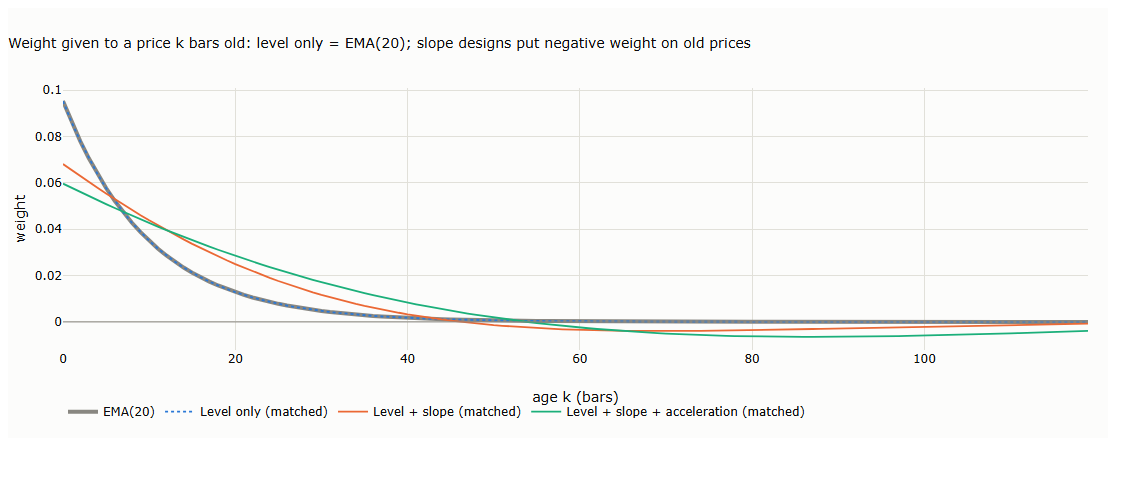

In [15]:
fig = go.Figure()
fig.add_scatter(x=np.arange(120), y=w_ema[:120], name="EMA(20)", mode="lines", line=dict(width=4, color=MUTED))
for j, k in enumerate((1, 2, 3)):
    fig.add_scatter(x=np.arange(120), y=level_weights(k, R_MATCH[k])[:120], name=f"{NAMES[k]} (matched)", mode="lines",
                    line=dict(width=1.8, color=SERIES[j], dash="dot" if k == 1 else "solid"))
fig.add_hline(y=0, line=dict(width=1, color=MUTED))
fig.update_layout(title="Weight given to a price k bars old: level only = EMA(20); slope designs put negative weight on old prices",
                  xaxis_title="age k (bars)", yaxis_title="weight", height=430, width=1100, margin=dict(t=80, b=70),
                  legend=dict(orientation="h", y=-0.18, x=0))
save_figure(fig, "c03_weights", FIG)
fig

**Memory in practice (§3.3; Table 3.3).** The settings of the charts were solved in section 2. The shortcut that
reads a memory off the gain fails for the slope:

In [16]:
# The gain is not a memory (Lecture 4b, section 3.3): set the slope gain to 2/(N+1) and measure the memory obtained.
K_ok, W_ok = steady_weights_k([ql_rel, qs_rel])
qs_short = bisect(lambda q: steady_weights_k([ql_rel, q])[0][1], 2 / 91, 1e-12, 1, increasing=True)
K_sh, W_sh = steady_weights_k([ql_rel, qs_short])
h_sh = tail_horizon(W_sh[:, 1])
N_sh = min(range(2, 400), key=lambda n: abs(ema_horizon(n) - h_sh))
print(f"slope memory EMA(90) by weights: slope gain {K_ok[1]:.4f} (2/91 = {2 / 91:.4f})")
print(f"slope gain set to 2/91 instead: slope horizon {h_sh} bars, the memory of about EMA({N_sh})")

slope memory EMA(90) by weights: slope gain 0.0023 (2/91 = 0.0220)
slope gain set to 2/91 instead: slope horizon 59 bars, the memory of about EMA(17)


## References

- Alizadeh, S., Brandt, M. and Diebold, F. (2002). Range-based estimation of stochastic volatility models. *Journal of Finance* 57(3), 1047–1091.
- Chan, E. (2013). *Algorithmic Trading: Winning Strategies and Their Rationale.* Wiley.
- Durbin, J. and Koopman, S.J. (2012). *Time Series Analysis by State Space Methods* (2nd ed.). Oxford University Press.
- Harvey, A. (1989). *Forecasting, Structural Time Series Models and the Kalman Filter.* Cambridge University Press.
- Julier, S. and Uhlmann, J. (1997). A new extension of the Kalman filter to nonlinear systems. *Proc. SPIE* 3068, 182–193.
- Julier, S. and Uhlmann, J. (2004). Unscented filtering and nonlinear estimation. *Proceedings of the IEEE* 92(3), 401–422.
- Kalman, R.E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering* 82(1), 35–45.
- Masreliez, C. and Martin, R.D. (1977). Robust Bayesian estimation for the linear model and robustifying the Kalman filter. *IEEE Transactions on Automatic Control* 22(3), 361–371.
- Mehra, R. (1970). On the identification of variances and adaptive Kalman filtering. *IEEE Transactions on Automatic Control* 15(2), 175–184.